# ModelGuard - AI Lifecycle Management and Governance Agent

## Project Overview

ModelGuard is a practical project that explores how machine learning models can be managed throughout their lifecycle. It combines basic MLOps practices with model monitoring, AI governance, and a local AI agent.

The project uses a customer churn prediction model as a case study. It aims to track model experiments and versions, monitor model performance, identify potential data changes, and support governance-related checks.

A local AI agent will interact with these components to interpret their outputs and provide recommendations. Important operations will remain subject to predefined rules and human approval.

## Project Objectives

- Build and evaluate a customer churn prediction model.
- Track experiments and model versions using MLflow.
- Monitor model pe
- rformance and detect data drift.
- Apply basic AI governance and risk assessment checks.
- Deploy the model locally through an API.
- Develop an AI agent to coordinate lifecycle and governance tasks.

## Notebook 01-Data Preparation and Churn Model

This notebook focuses on preparing the customer churn dataset, exploring its main characteristics, and developing the initial machine learning model.

## Environment Setup

Prepares the working environment for the analysis. The required libraries are imported, the random seed is set to ensure reproducibility, and the main project directories are defined.

In [2]:
# Import required libraries
import os
import sys
import random
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import mlflow

# Set random seed for reproducibility
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# Define project directories
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

# Display environment information
print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("MLflow version:", mlflow.__version__)

print("\nProject root:", PROJECT_ROOT)
print("Environment setup completed successfully.")


Python version: 3.12.10
Pandas version: 3.1.1
NumPy version: 2.5.5
Scikit-learn version: 1.9.1
MLflow version: 3.18.0

Project root: C:\Users\User\ModelGuard
Environment setup completed successfully.



## Import Data

Introduces the dataset used in the project. The original CSV file is downloaded from IBM's public repository and stored locally for further analysis.



### Loading the Dataset

The dataset is loaded into a Pandas DataFrame. A raw copy is also saved locally to preserve the original data before applying any preprocessing steps.


In [3]:

import requests
from pathlib import Path

# Define dataset source and local path
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "IBM/telco-customer-churn-on-icp4d/"
    "master/data/Telco-Customer-Churn.csv"
)

DATA_PATH = DATA_RAW / "Telco-Customer-Churn.csv"

# Download the dataset if it does not exist locally
if not DATA_PATH.exists():
    response = requests.get(DATA_URL, timeout=30)
    response.raise_for_status()

    DATA_PATH.write_bytes(response.content)
    print("Dataset downloaded successfully.")
else:
    print("Dataset already exists locally.")

# Load the dataset
df_raw = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df_raw.shape)
print("File size:", round(DATA_PATH.stat().st_size / 1024, 2), "KB")

# Display the first five records
display(df_raw.head())


Dataset already exists locally.
Dataset loaded successfully.
Dataset shape: (7043, 21)
File size: 947.71 KB


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Initial Data Inspection

In [4]:
df_raw.info()

print("\nMissing values per column:")
display(
    df_raw.isnull().sum()
    .to_frame(name="Missing Values")
    .sort_values(by="Missing Values", ascending=False)
)

print("\nNumber of duplicate rows:", df_raw.duplicated().sum())

display(df_raw.describe(include="all").T)

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

,Missing Values
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0



Number of duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN



### Data Quality Investigation

The initial inspection revealed that the `TotalCharges` column is stored as text instead of a numeric variable. This section investigates blank values, checks their relationship with customer tenure, and examines the distribution of the target variable before preprocessing.


#### Investigating TotalCharges

In [5]:

# Identify blank or whitespace-only values
blank_total_charges = (
    df_raw["TotalCharges"]
    .astype("string")
    .str.strip()
    .eq("")
)

print("Blank TotalCharges values:", blank_total_charges.sum())

# Convert TotalCharges to numeric
total_charges_numeric = pd.to_numeric(
    df_raw["TotalCharges"].str.strip(),
    errors="coerce"
)

print(
    "Non-numeric or missing values after conversion:",
    total_charges_numeric.isna().sum()
)

# Examine affected records
display(
    df_raw.loc[
        total_charges_numeric.isna(),
        ["customerID", "tenure", "TotalCharges", "Churn"]
    ]
)


Blank TotalCharges values: 11
Non-numeric or missing values after conversion: 11


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,,No
753,3115-CZMZD,0,,No
936,5709-LVOEQ,0,,No
1082,4367-NUYAO,0,,No
1340,1371-DWPAZ,0,,No
3331,7644-OMVMY,0,,No
3826,3213-VVOLG,0,,No
4380,2520-SGTTA,0,,No
5218,2923-ARZLG,0,,No
6670,4075-WKNIU,0,,No


#### Checking the Target Distribution

,Customer Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


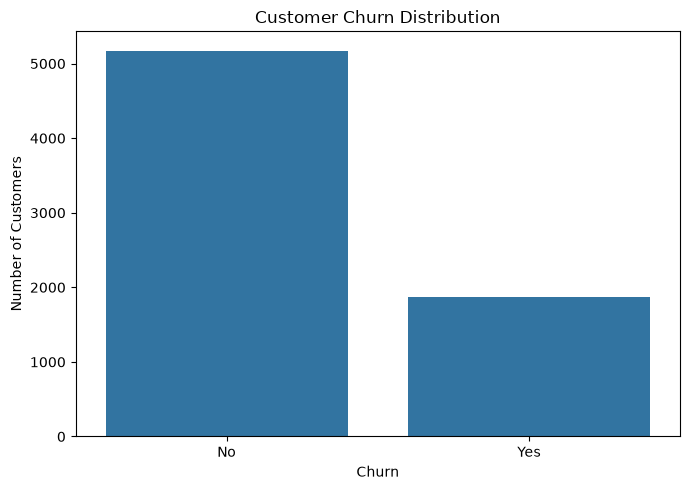

In [6]:
# Calculate churn distribution
churn_counts = df_raw["Churn"].value_counts()

churn_percentage = (
    df_raw["Churn"]
    .value_counts(normalize=True) * 100
)

churn_summary = pd.DataFrame({
    "Customer Count": churn_counts,
    "Percentage": churn_percentage.round(2)
})

display(churn_summary)

# Visualize target distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_raw,
    x="Churn"
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

## Data Cleaning

This section addresses the data quality issues identified during the initial inspection. The main focus is converting numerical columns to the correct data types and handling the blank values found in `TotalCharges`.

### Handling TotalCharges

The inspection identified 11 blank values in `TotalCharges`. All affected customers have a tenure of zero months. These values will be replaced with zero because no accumulated charges are recorded for these customers.

In [7]:
# Create a separate copy for cleaning
df = df_raw.copy()

# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].astype("string").str.strip(),
    errors="coerce"
)

# Check affected records
affected_records = df["TotalCharges"].isna()

print("Missing TotalCharges before treatment:",
      affected_records.sum())

print("Affected customers with zero tenure:",
      (df.loc[affected_records, "tenure"] == 0).all())

# Replace missing values with zero
df.loc[affected_records, "TotalCharges"] = 0

# Convert to numeric type
df["TotalCharges"] = df["TotalCharges"].astype(float)

# Verify the cleaning results
print("\nMissing values after treatment:",
      df["TotalCharges"].isna().sum())

print("TotalCharges data type:",
      df["TotalCharges"].dtype)

print("Cleaned dataset shape:", df.shape)

Missing TotalCharges before treatment: 11
Affected customers with zero tenure: True

Missing values after treatment: 0
TotalCharges data type: float64
Cleaned dataset shape: (7043, 21)


### Validate the Cleaned Dataset

In [8]:
# Check missing values across all columns
missing_summary = df.isnull().sum()

print("Total missing values:", missing_summary.sum())

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# Verify numerical columns
display(df[["tenure", "MonthlyCharges", "TotalCharges"]].describe())

# Review the previously affected records
display(
    df.loc[
        affected_records,
        ["customerID", "tenure", "TotalCharges", "Churn"]
    ]
)

Total missing values: 0
Duplicate rows: 0


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


,customerID,tenure,TotalCharges,Churn
488,4472-LVYGI,0,0.0,No
753,3115-CZMZD,0,0.0,No
936,5709-LVOEQ,0,0.0,No
1082,4367-NUYAO,0,0.0,No
1340,1371-DWPAZ,0,0.0,No
3331,7644-OMVMY,0,0.0,No
3826,3213-VVOLG,0,0.0,No
4380,2520-SGTTA,0,0.0,No
5218,2923-ARZLG,0,0.0,No
6670,4075-WKNIU,0,0.0,No


### Initial Data Inspection and Cleaning – Results and Discussion

The dataset contains 7,043 customer records and 21 columns, including customer information, services, contracts, and billing details. The target variable is `Churn`, which indicates whether a customer has left the company. During data inspection, 11 blank values were identified in `TotalCharges`. Since all affected customers had zero tenure, these values were replaced with zero. After cleaning, the dataset contained no missing values or duplicate rows, while the original data remained unchanged.


## Exploratory Data Analysis (EDA)

Explores the cleaned dataset to understand customer characteristics and identify patterns related to churn. Numerical and categorical features are examined to better understand customer behavior before model development.

### Numerical Features Analysis

Examines the distribution of numerical features across churn groups. Boxplots are used to compare customer tenure, monthly charges, and total charges.

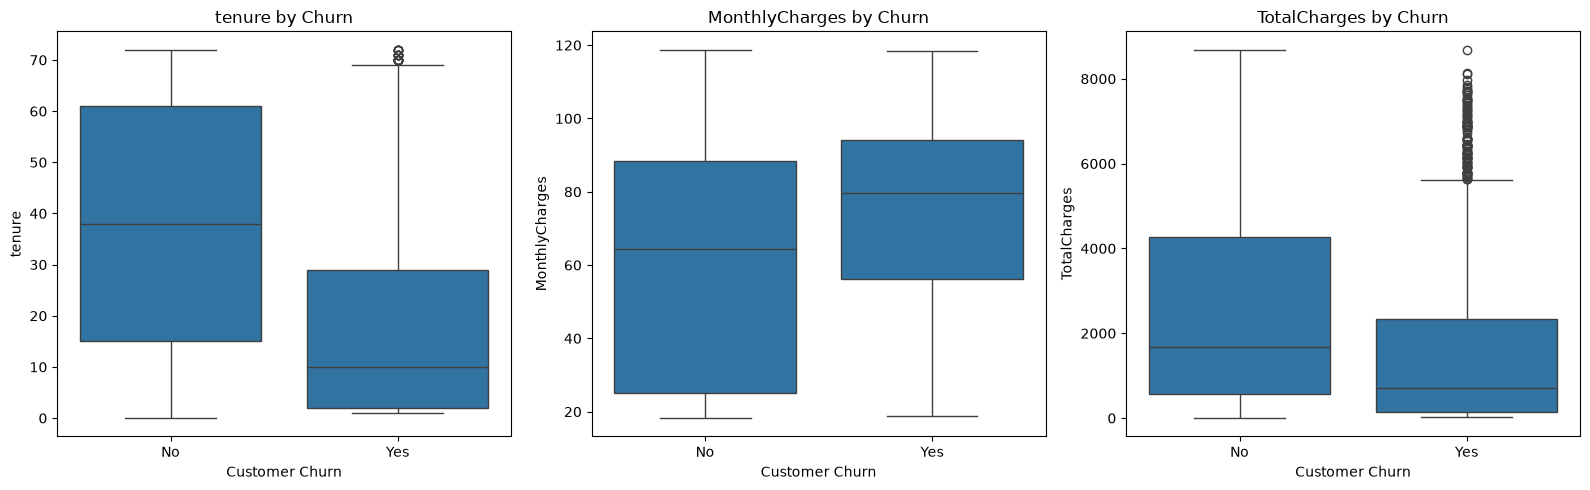

In [9]:
# Select numerical features
numerical_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Compare numerical features by churn status
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, feature in zip(axes, numerical_features):
    sns.boxplot(
        data=df,
        x="Churn",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} by Churn")
    ax.set_xlabel("Customer Churn")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

### Numerical Features – Results and Discussion

The analysis shows clear differences between customers who stayed and those who left. Customers who churned generally had shorter subscription periods and higher monthly charges. However, their total charges were lower, which is consistent with their shorter tenure. These patterns suggest that customer tenure and monthly charges may be useful features for predicting churn.



### Categorical Features Analysis

Examines how churn rates vary across different contract types, internet services, and payment methods. The analysis uses percentages to make comparisons between customer groups more meaningful.


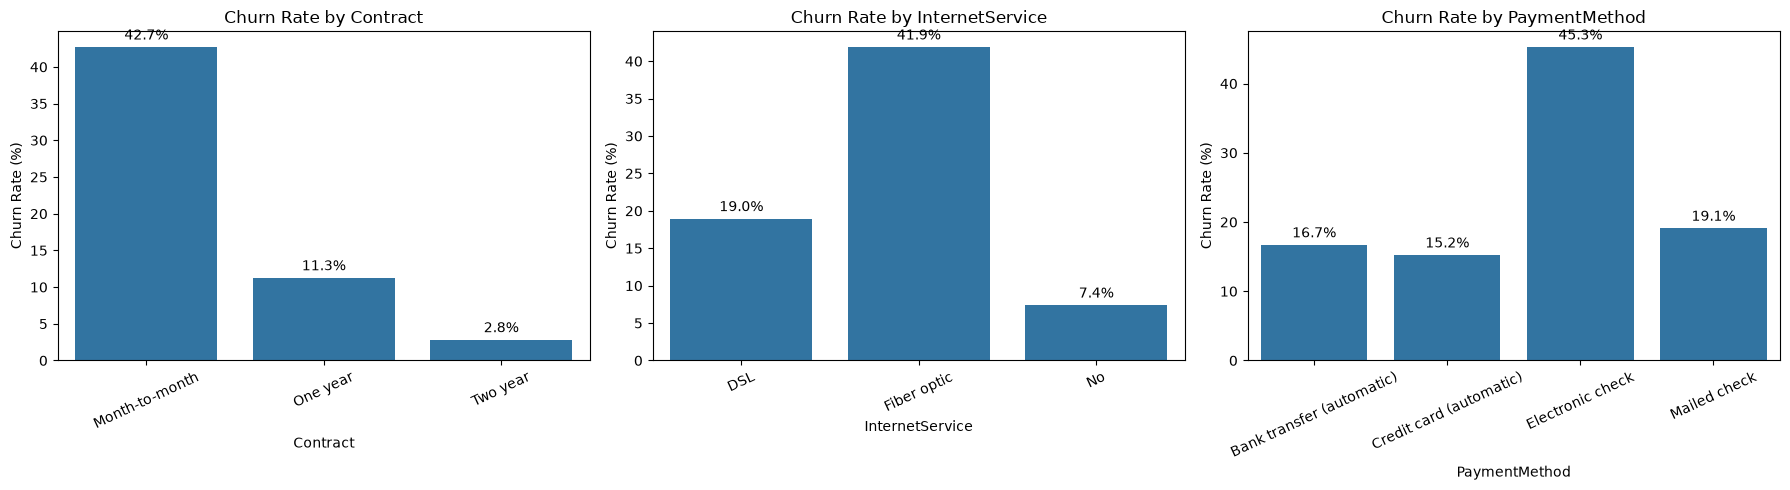

In [10]:
# Select categorical features
categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod"
]

# Calculate and visualize churn rates
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, feature in zip(axes, categorical_features):

    churn_rate = (
        df.groupby(feature, observed=True)["Churn"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .reset_index(name="Churn Rate")
    )

    sns.barplot(
        data=churn_rate,
        x=feature,
        y="Churn Rate",
        ax=ax
    )

    ax.set_title(f"Churn Rate by {feature}")
    ax.set_ylabel("Churn Rate (%)")
    ax.set_xlabel(feature)
    ax.tick_params(axis="x", rotation=25)

    # Display percentages on bars
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()


### Categorical Features – Results and Discussion

The analysis shows that churn rates vary across customer groups. Month-to-month contracts have the highest churn rate, while two-year contracts have the lowest. Customers using Fiber optic services and Electronic check payments also show higher churn rates than other groups. These findings highlight contract type, internet service, and payment method as potentially useful features for churn prediction.



### Churn Rate and Customer Count Analysis

The churn percentages are reviewed alongside the number of customers in each category. This provides additional context and helps avoid interpreting percentages without considering group size.


In [11]:

# Compare customer counts and churn rates
features_to_check = [
    "Contract",
    "InternetService",
    "PaymentMethod"
]

for feature in features_to_check:

    summary = (
        df.groupby(feature, observed=True)
        .agg(
            Total_Customers=("Churn", "size"),
            Churned_Customers=(
                "Churn",
                lambda x: (x == "Yes").sum()
            )
        )
    )

    summary["Churn_Rate"] = (
        summary["Churned_Customers"]
        / summary["Total_Customers"] * 100
    ).round(2)

    print(f"\n{feature} Analysis")
    display(summary)



Contract Analysis


,Total_Customers,Churned_Customers,Churn_Rate
Contract,,,
Month-to-month,3875,1655,42.71
One year,1473,166,11.27
Two year,1695,48,2.83



InternetService Analysis


,Total_Customers,Churned_Customers,Churn_Rate
InternetService,,,
DSL,2421,459,18.96
Fiber optic,3096,1297,41.89
No,1526,113,7.40



PaymentMethod Analysis


,Total_Customers,Churned_Customers,Churn_Rate
PaymentMethod,,,
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11


### Customer Count Analysis – Results and Discussion

The customer counts support the patterns observed in the previous analysis. Month-to-month contracts, Fiber optic services, and Electronic check payments show higher churn rates than their respective alternatives. Electronic check has the highest churn rate at 45.29%, followed by month-to-month contracts at 42.71% and Fiber optic services at 41.89%. These features will be retained for model development because they may provide useful information for predicting customer churn.


### Feature Correlation Analysis

Examines the correlation between numerical features and the target variable. A correlation matrix and heatmap are used to identify the strength and direction of linear relationships between variables.


In [12]:
# Create a copy for correlation analysis
correlation_df = df.copy()

# Encode the target variable
correlation_df["Churn"] = correlation_df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Select numerical features
correlation_features = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "Churn"
]

# Calculate Pearson correlation
correlation_matrix = correlation_df[
    correlation_features
].corr(method="pearson")

display(correlation_matrix.round(3))


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn
SeniorCitizen,1.000,0.017,0.220,0.103,0.151
tenure,0.017,1.000,0.248,0.826,-0.352
MonthlyCharges,0.220,0.248,1.000,0.651,0.193
TotalCharges,0.103,0.826,0.651,1.000,-0.198
Churn,0.151,-0.352,0.193,-0.198,1.000


#### Correlation Heatmap

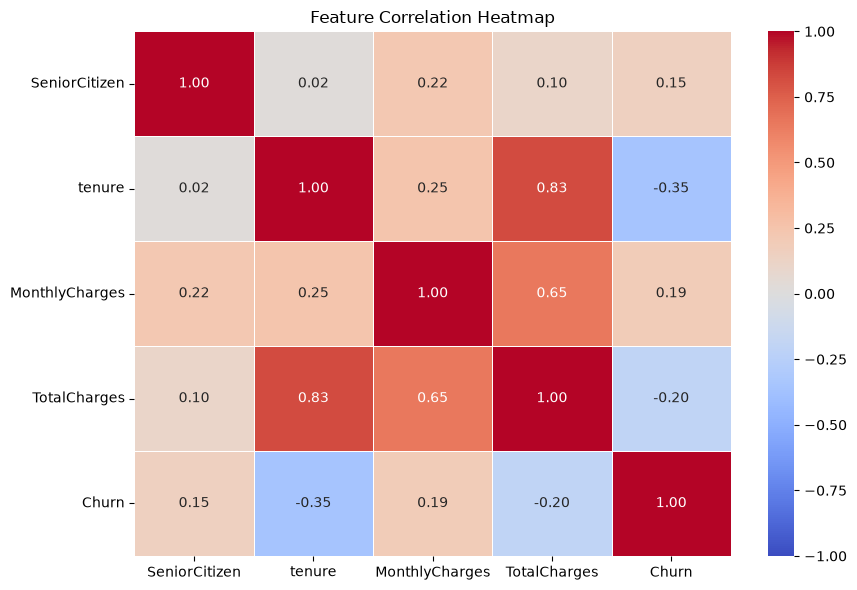

In [13]:

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


#### Correlation with Churn

In [14]:
churn_correlation = (
    correlation_matrix["Churn"]
    .drop("Churn")
    .sort_values(key=abs, ascending=False)
)

display(
    churn_correlation.to_frame(
        name="Correlation with Churn"
    ).round(3)
)

,Correlation with Churn
tenure,-0.352
TotalCharges,-0.198
MonthlyCharges,0.193
SeniorCitizen,0.151


### Feature Correlation Analysis – Results and Discussion

The correlation analysis shows that tenure has the strongest relationship with churn, with a negative correlation of -0.352. MonthlyCharges and SeniorCitizen have weak positive correlations, while TotalCharges has a weak negative correlation.

A strong positive correlation was also observed between tenure and TotalCharges (0.826). This relationship may indicate potential multicollinearity during model development and will be considered when evaluating the model.

Overall, the results provide an initial understanding of the relationships between numerical features and customer churn.

## Data Preprocessing

This section prepares the dataset for machine learning. It includes separating the target variable, removing unnecessary identifiers, splitting the data into training and testing sets, and preparing numerical and categorical features for model training.


### Separating Features and Target

The target variable is separated from the input features. The customerID column is removed because it is used only to identify customers and does not represent a meaningful predictive feature.


In [15]:
# Separate input features and target variable
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Display dataset dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
display(y.value_counts().rename({
    0: "No Churn",
    1: "Churn"
}))

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:


Churn
No Churn    5174
Churn       1869
Name: count, dtype: int64


### Train-Test Split

The dataset is divided into training and testing sets using an 80:20 ratio. Stratified sampling is applied to maintain the original churn distribution in both sets. A fixed random state is also used to ensure reproducibility.


In [16]:

from sklearn.model_selection import train_test_split

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display split dimensions
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).mul(100).round(2))


Training features: (5634, 19)
Testing features: (1409, 19)

Training target distribution:


Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


Testing target distribution:


Churn
0    73.46
1    26.54
Name: proportion, dtype: float64


### Feature Type Identification

Numerical and categorical features require different preprocessing methods. Numerical variables will be standardized, while categorical variables will be converted into numerical representations using One-Hot Encoding.


In [17]:

# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

print("\nNumber of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))


Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of numerical features: 4
Number of categorical features: 15



### Building the Preprocessing Pipeline

Numerical and categorical features are processed separately using a ColumnTransformer. Numerical features are standardized, while categorical features are encoded using One-Hot Encoding. All transformations are fitted on the training data only to prevent data leakage.


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = StandardScaler()

# Categorical preprocessing
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


### Model Evaluation Using Cross-Validation

Evaluates Logistic Regression using five-fold stratified cross-validation. Two configurations are compared: the standard model and a model using balanced class weights. The comparison helps determine whether class weighting improves the detection of customers who are likely to churn.

In [19]:

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define cross-validation strategy
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Define evaluation metrics
scoring = {
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

# Define model configurations
models = {
    "Baseline": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),

    "Balanced": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )
}

# Evaluate both configurations
cv_results = []

for model_name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    result = {"Model": model_name}

    for metric in scoring:
        result[metric] = scores[f"test_{metric}"].mean()
        result[f"{metric}_std"] = scores[f"test_{metric}"].std()

    cv_results.append(result)

# Display comparison
cv_comparison = pd.DataFrame(cv_results)

display(
    cv_comparison.set_index("Model").round(4)
)


,precision,precision_std,recall,recall_std,f1,f1_std,roc_auc,roc_auc_std,pr_auc,pr_auc_std
Model,,,,,,,,,,
Baseline,0.6529,0.0262,0.5431,0.0411,0.5923,0.0299,0.8462,0.0126,0.6617,0.0194
Balanced,0.5169,0.0189,0.8013,0.0379,0.6283,0.0232,0.8460,0.0124,0.6600,0.0195



### Cross-Validation - Results and Discussion

The cross-validation results show that class weighting improved the model's ability to identify customers who are likely to churn. Recall increased from 54.31% to 80.13%, while the F1-score improved from 0.5923 to 0.6283. However, Precision decreased from 65.29% to 51.69%. ROC-AUC and PR-AUC remained nearly unchanged. Based on these results, the balanced configuration was selected for further evaluation because it provides better recall and F1-score.


### Threshold Optimization

The default classification threshold is 0.5, but it may not provide the best balance between precision and recall. This section evaluates different classification thresholds using out-of-fold predictions generated from the training data. The goal is to identify a threshold that improves the F1-score without using the test set.

In [20]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

# Create the balanced Logistic Regression pipeline
balanced_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Generate out-of-fold probabilities
oof_probabilities = cross_val_predict(
    balanced_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Out-of-fold predictions generated:", len(oof_probabilities))


Out-of-fold predictions generated: 5634


In [21]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Define candidate thresholds
thresholds = np.arange(0.20, 0.81, 0.02)

threshold_results = []

for threshold in thresholds:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_train, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_train, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

# Select threshold with the highest F1-score
best_result = threshold_df.loc[
    threshold_df["F1-score"].idxmax()
]

best_threshold = best_result["Threshold"]

display(threshold_df.round(4))

print("\nBest threshold:", round(best_threshold, 2))
print("Best F1-score:", round(best_result["F1-score"], 4))


,Threshold,Precision,Recall,F1-score
0,0.20,0.3863,0.9552,0.5501
1,0.22,0.3934,0.9458,0.5557
2,0.24,0.4013,0.9431,0.5630
3,0.26,0.4068,0.9344,0.5668
4,0.28,0.4155,0.9298,0.5744
5,0.30,0.4244,0.9258,0.5820
6,0.32,0.4336,0.9217,0.5898
7,0.34,0.4411,0.9097,0.5941
8,0.36,0.4513,0.8983,0.6008
9,0.38,0.4595,0.8843,0.6048



Best threshold: 0.6
Best F1-score: 0.637


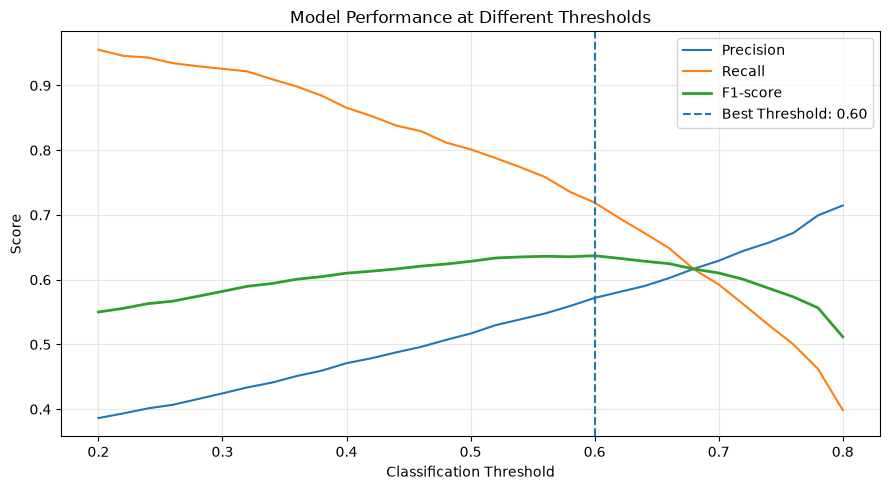

In [22]:

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-score"],
    label="F1-score",
    linewidth=2
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best Threshold: {best_threshold:.2f}"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Model Performance at Different Thresholds")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



### Threshold Optimization – Results and Discussion

The threshold analysis identified 0.60 as the value that achieved the highest F1-score of 0.637. Compared with the default threshold of 0.50, Precision increased from 51.68% to 57.18%, while Recall decreased from 80.13% to 71.91%. The F1-score improved slightly from 0.6284 to 0.6370. This indicates a trade-off between identifying more churn customers and reducing false positive predictions. The threshold of 0.60 was selected for further evaluation.


### Final Model Evaluation

The selected Logistic Regression configuration is trained on the complete training set and evaluated on the unseen test set. Both the default threshold and the selected threshold are examined to compare their impact on classification performance.

In [23]:

# Define the selected classification threshold
best_threshold = 0.60

# Train the final balanced Logistic Regression pipeline
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

# Generate probabilities on the test set
test_probabilities = final_model.predict_proba(X_test)[:, 1]

print("Final model trained successfully.")
print("Selected threshold:", best_threshold)


Final model trained successfully.
Selected threshold: 0.6


In [46]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

test_results = []

for threshold in [0.50, best_threshold]:

    test_predictions = (
        test_probabilities >= threshold
    ).astype(int)

    test_results.append({
        "Threshold": threshold,
        "accuracy" : accuracy_score(y_test, test_predictions),
        "Precision": precision_score(y_test, test_predictions),
        "Recall": recall_score(y_test, test_predictions),
        "F1-score": f1_score(y_test, test_predictions),
        "ROC-AUC": roc_auc_score(y_test, test_probabilities),
        "PR-AUC": average_precision_score(y_test, test_probabilities)
    })

test_comparison = pd.DataFrame(test_results)

display(test_comparison.round(4))


,Threshold,accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,0.5,0.7381,0.5043,0.7834,0.6136,0.8416,0.6327
1,0.6,0.7622,0.5399,0.7059,0.6118,0.8416,0.6327


### confusion matrix

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.88      0.78      0.83      1035
       Churn       0.54      0.71      0.61       374

    accuracy                           0.76      1409
   macro avg       0.71      0.74      0.72      1409
weighted avg       0.79      0.76      0.77      1409



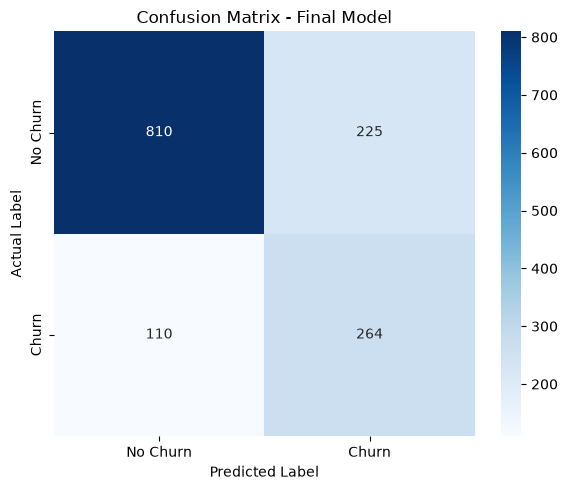

In [25]:

# Generate predictions using the selected threshold
final_predictions = (
    test_probabilities >= best_threshold
).astype(int)

# Display classification report
print("Classification Report:")
print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["No Churn", "Churn"]
    )
)

# Plot confusion matrix
cm = confusion_matrix(y_test, final_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Confusion Matrix - Final Model")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()



### Receiver Operating Characteristic (ROC) Curve

The ROC curve evaluates the model's ability to distinguish between churn and non-churn customers across different classification thresholds. The Area Under the Curve (AUC) is used to summarize the model's discrimination performance.


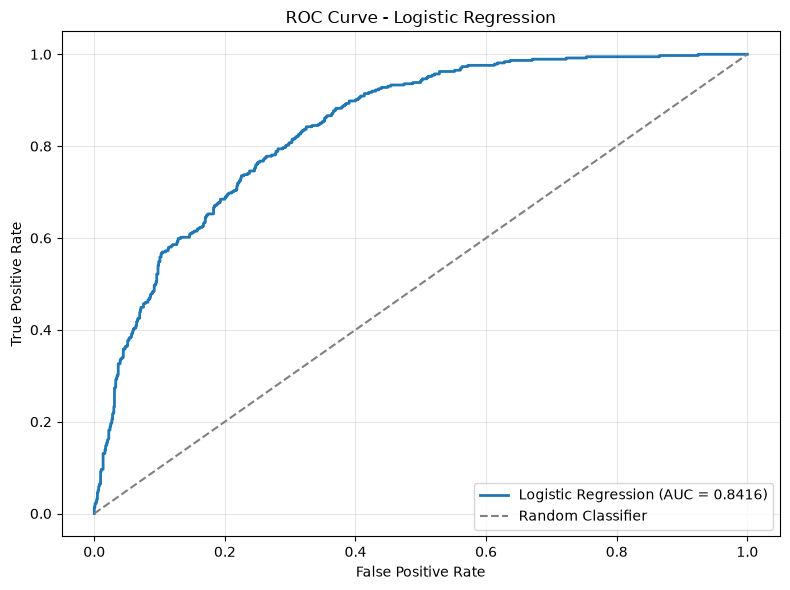

ROC-AUC: 0.8416


In [26]:

from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve values
fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probabilities
)

# Calculate ROC-AUC
roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.4f})",
    linewidth=2
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.4f}")


### Logistic Regression – Model Evaluation Results

The Logistic Regression model was evaluated using 5-fold Stratified Cross-Validation and an independent test set. To address class imbalance, `class_weight="balanced"` was applied, improving Recall from 54.31% to 80.13% and F1-score from 59.23% to 62.83% during cross-validation. Threshold optimization identified 0.60 as the best threshold based on the highest cross-validation F1-score of 63.70%. On the test set, the model achieved 76.22% Accuracy, 53.99% Precision, 70.59% Recall, and 61.18% F1-score. The ROC-AUC was 0.8416, while PR-AUC reached 0.6327. The confusion matrix showed 810 True Negatives, 264 True Positives, 225 False Positives, and 110 False Negatives. Overall, the model demonstrated a good ability to distinguish between churn and non-churn customers, although its Precision and F1-score indicate that further improvement is needed. Therefore, Logistic Regression will be retained as the baseline model for comparison with other algorithms.

## XGBoost Model Development

This section introduces XGBoost as an additional classification algorithm for customer churn prediction. Its performance will be compared with Logistic Regression to determine whether a tree-based boosting approach can improve prediction results.

### Installing and Importing XGBoost

In [27]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [28]:

import xgboost as xgb

print("XGBoost version:", xgb.__version__)


XGBoost version: 3.4.1


### Handling Class Imbalance

In [29]:
# Calculate class weight from training data
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()

scale_pos_weight = negative_count / positive_count

print("Negative samples:", negative_count)
print("Positive samples:", positive_count)
print("Scale pos weight:", round(scale_pos_weight, 4))

Negative samples: 4139
Positive samples: 1495
Scale pos weight: 2.7686


### Building the XGBoost Pipeline

In [30]:

from xgboost import XGBClassifier

# Preprocessing for XGBoost
xgb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

# Define XGBoost model
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

# Create complete pipeline
xgb_pipeline = Pipeline([
    ("preprocessor", xgb_preprocessor),
    ("classifier", xgb_model)
])

print("XGBoost pipeline created successfully.")


XGBoost pipeline created successfully.


### Cross-Validation Evaluation

In [31]:

# Evaluate XGBoost using cross-validation
xgb_scores = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Calculate mean and standard deviation
xgb_result = {"Model": "XGBoost"}

for metric in scoring:
    xgb_result[metric] = xgb_scores[f"test_{metric}"].mean()
    xgb_result[f"{metric}_std"] = xgb_scores[f"test_{metric}"].std()

xgb_cv_results = pd.DataFrame([xgb_result])

display(xgb_cv_results.set_index("Model").round(4))


,precision,precision_std,recall,recall_std,f1,f1_std,roc_auc,roc_auc_std,pr_auc,pr_auc_std
Model,,,,,,,,,,
XGBoost,0.5327,0.0073,0.7759,0.0208,0.6316,0.0096,0.8444,0.0089,0.6627,0.0178


### XGBoost – Cross-Validation Results and Discussion

XGBoost achieved a Precision of 53.27%, Recall of 77.59%, and F1-score of 0.6316 during five-fold cross-validation. Its ROC-AUC and PR-AUC reached 0.8444 and 0.6627, respectively. Compared with Logistic Regression, XGBoost showed slightly higher Precision, F1-score, and PR-AUC, while Logistic Regression achieved higher Recall and ROC-AUC. Overall, the two models demonstrated similar performance, with XGBoost providing a small improvement in F1-score. Further evaluation is required before selecting the final model.


### XGBoost Hyperparameter Tuning

Applies a small hyperparameter search to improve the XGBoost model. Different combinations of model parameters are evaluated using five-fold stratified cross-validation. The F1-score is used as the selection metric to balance precision and recall.


In [32]:

from sklearn.model_selection import RandomizedSearchCV

# Define parameter search space
param_grid = {
    "classifier__n_estimators": [200, 300],
    "classifier__max_depth": [3, 4],
    "classifier__learning_rate": [0.05, 0.1],
    "classifier__min_child_weight": [1, 3]
}

# Configure randomized search
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=8,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Run search using training data only
xgb_search.fit(X_train, y_train)

print("Best Parameters:")
print(xgb_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(round(xgb_search.best_score_, 4))


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters:
{'classifier__n_estimators': 200, 'classifier__min_child_weight': 1, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05}

Best Cross-Validation F1-score:
0.6327


### Hyperparameter Tuning – Results and Discussion

A randomized hyperparameter search was performed using eight parameter combinations and five-fold stratified cross-validation, resulting in 40 model fits. The best configuration used 200 estimators, a maximum depth of 3, a learning rate of 0.05, and a minimum child weight of 1. The best F1-score was 0.6327, compared with 0.6316 before tuning. This represents a very small improvement, suggesting that the initial XGBoost configuration was already close to the best result within the tested parameter range.

### Threshold Optimization

In [33]:
tuned_xgb_model = xgb_search.best_estimator_

# Generate out-of-fold probabilities for tuned XGBoost
xgb_oof_probabilities = cross_val_predict(
    tuned_xgb_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Evaluate different thresholds
xgb_threshold_results = []

for threshold in np.arange(0.20, 0.81, 0.02):

    predictions = (
        xgb_oof_probabilities >= threshold
    ).astype(int)

    xgb_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_train, predictions),
        "Recall": recall_score(y_train, predictions),
        "F1-score": f1_score(y_train, predictions)
    })

xgb_threshold_df = pd.DataFrame(xgb_threshold_results)

# Select the threshold with the highest F1-score
xgb_best_result = xgb_threshold_df.loc[
    xgb_threshold_df["F1-score"].idxmax()
]

xgb_best_threshold = xgb_best_result["Threshold"]

display(xgb_threshold_df.round(4))

print("Best XGBoost threshold:", round(xgb_best_threshold, 2))
print("Best F1-score:", round(xgb_best_result["F1-score"], 4))


,Threshold,Precision,Recall,F1-score
0,0.20,0.3956,0.9431,0.5574
1,0.22,0.4032,0.9358,0.5635
2,0.24,0.4101,0.9244,0.5681
3,0.26,0.4205,0.9184,0.5769
4,0.28,0.4294,0.9130,0.5841
5,0.30,0.4361,0.9043,0.5885
6,0.32,0.4455,0.8990,0.5957
7,0.34,0.4534,0.8916,0.6011
8,0.36,0.4637,0.8809,0.6076
9,0.38,0.4711,0.8716,0.6116


Best XGBoost threshold: 0.56
Best F1-score: 0.6385


### XGBoost Threshold Optimization - Results and Discussion

The threshold optimization identified 0.56 as the best
threshold for the XGBoost model, achieving an F1-score
of 0.6385.

At this threshold, the model achieved a precision of
0.5567 and a recall of 0.7485.

Compared with Logistic Regression, XGBoost achieved
a slightly higher F1-score. However, the difference
was very small, indicating that both models have
similar performance.

The selected threshold will be used for the final
evaluation on the independent test set.

### Final Test Evaluation

In [34]:
# Generate predictions using the selected threshold
xgb_test_probabilities = tuned_xgb_model.predict_proba(X_test)[:, 1]

xgb_test_predictions = (
    xgb_test_probabilities >= xgb_best_threshold
).astype(int)

# Evaluate the model
xgb_test_results = {
    "Accuracy": accuracy_score(y_test, xgb_test_predictions),
    "Precision": precision_score(y_test, xgb_test_predictions),
    "Recall": recall_score(y_test, xgb_test_predictions),
    "F1-score": f1_score(y_test, xgb_test_predictions),
    "ROC-AUC": roc_auc_score(y_test, xgb_test_probabilities),
    "PR-AUC": average_precision_score(y_test, xgb_test_probabilities)
}

display(pd.DataFrame([xgb_test_results]).round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,0.7644,0.5407,0.746,0.627,0.8463,0.6622


### Confusion Matrix

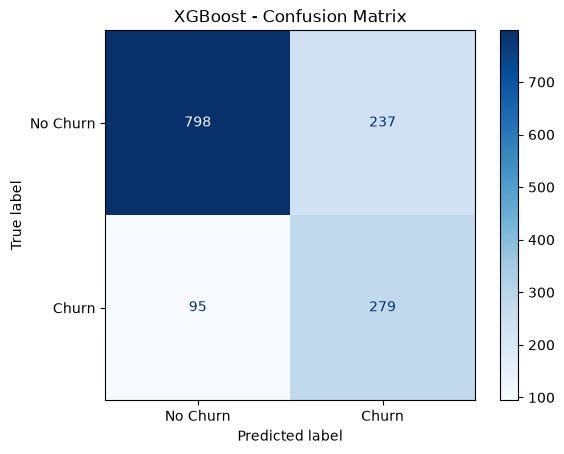

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
xgb_cm = confusion_matrix(y_test, xgb_test_predictions)

# Plot confusion matrix
xgb_cm_display = ConfusionMatrixDisplay(
    confusion_matrix=xgb_cm,
    display_labels=["No Churn", "Churn"]
)

xgb_cm_display.plot(cmap="Blues", values_format="d")
plt.title("XGBoost - Confusion Matrix")
plt.show()

### ROC Curve

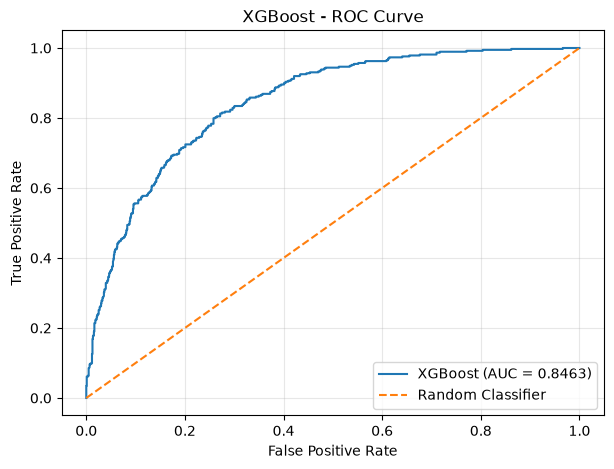

In [36]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_test,
    xgb_test_probabilities
)

# Calculate ROC-AUC
xgb_roc_auc = roc_auc_score(
    y_test,
    xgb_test_probabilities
)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost (AUC = {xgb_roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost - ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### XGBoost - Model Evaluation Results

The XGBoost model achieved an accuracy of 76.44%, precision of 54.07%, recall of 74.60%, and an F1-score of 62.70% on the test dataset, using an optimized classification threshold of 0.56. The confusion matrix showed that the model correctly classified 798 non-churn customers and identified 279 churn customers, while 237 non-churn customers were incorrectly classified as churners and 95 actual churn customers were missed. Furthermore, the ROC-AUC score of 0.8463 indicates good discrimination between churn and non-churn customers. Overall, the model demonstrated a good ability to identify customers at risk of leaving the service, although some incorrect predictions remain.

### Random Undersampling Experiment

In [37]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [38]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.base import clone
from xgboost import XGBClassifier

# Reuse the preprocessing and best hyperparameters
xgb_preprocessor = clone(
    tuned_xgb_model.named_steps["preprocessor"]
)

xgb_parameters = (
    tuned_xgb_model.named_steps["classifier"].get_params()
)

# Disable class weighting because undersampling handles imbalance
xgb_parameters["scale_pos_weight"] = 1

# Create the undersampling pipeline
undersampled_xgb = ImbPipeline([
    ("preprocessor", xgb_preprocessor),
    ("sampler", RandomUnderSampler(random_state=42)),
    ("classifier", XGBClassifier(**xgb_parameters))
])

print("Undersampling XGBoost pipeline created successfully.")

Undersampling XGBoost pipeline created successfully.


In [39]:
undersampling_cv_results = cross_validate(
    undersampled_xgb,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

undersampling_summary = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"],
    "Mean Score": [
        undersampling_cv_results["test_precision"].mean(),
        undersampling_cv_results["test_recall"].mean(),
        undersampling_cv_results["test_f1"].mean(),
        undersampling_cv_results["test_roc_auc"].mean(),
        undersampling_cv_results["test_pr_auc"].mean()
    ],
    "Std": [
        undersampling_cv_results["test_precision"].std(),
        undersampling_cv_results["test_recall"].std(),
        undersampling_cv_results["test_f1"].std(),
        undersampling_cv_results["test_roc_auc"].std(),
        undersampling_cv_results["test_pr_auc"].std()
    ]
})

display(undersampling_summary.round(4))

,Metric,Mean Score,Std
0,Precision,0.5174,0.0148
1,Recall,0.8060,0.0172
2,F1-score,0.6302,0.0142
3,ROC-AUC,0.8476,0.0106
4,PR-AUC,0.6622,0.0226


### Random Undersampling Experiment - Results and 

Random Undersampling was tested to investigate
whether reducing the majority class could improve
the model's performance.

The results showed an increase in recall from
0.7759 to 0.8060. However, precision decreased
from 0.5327 to 0.5174, while the F1-score slightly
decreased from 0.6316 to 0.6302.

The ROC-AUC improved slightly, while PR-AUC
remained almost unchanged.

Based on these results, Random Undersampling did
not provide an overall improvement. Therefore,
the original XGBoost model using scale_pos_weight
was retained as the preferred model.

### Train the Final Model

In [40]:
from sklearn.base import clone

# Create and train the final XGBoost model
final_xgb_model = clone(tuned_xgb_model)

final_xgb_model.fit(X_train, y_train)

# Selected classification threshold
final_threshold = 0.56

print("Final XGBoost model trained successfully.")

Final XGBoost model trained successfully.


### Generate Test Predictions

In [41]:
# Predict churn probabilities
final_test_probabilities = final_xgb_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
final_test_predictions = (
    final_test_probabilities >= final_threshold
).astype(int)

### Calculate Final Evaluation Metrics

In [42]:
final_evaluation = pd.DataFrame([{
    "Accuracy": accuracy_score(y_test, final_test_predictions),
    "Precision": precision_score(y_test, final_test_predictions),
    "Recall": recall_score(y_test, final_test_predictions),
    "F1-score": f1_score(y_test, final_test_predictions),
    "ROC-AUC": roc_auc_score(y_test, final_test_probabilities),
    "PR-AUC": average_precision_score(y_test, final_test_probabilities)
}])

display(final_evaluation.round(4))

,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,0.7644,0.5407,0.746,0.627,0.8463,0.6622


### Confusion Matrix

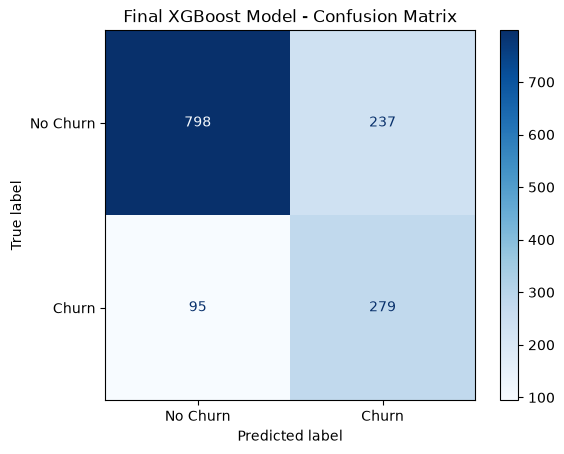

In [43]:
from sklearn.metrics import ConfusionMatrixDisplay

final_cm = confusion_matrix(y_test, final_test_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=["No Churn", "Churn"]
).plot(cmap="Blues", values_format="d")

plt.title("Final XGBoost Model - Confusion Matrix")
plt.show()

### ROC Curve

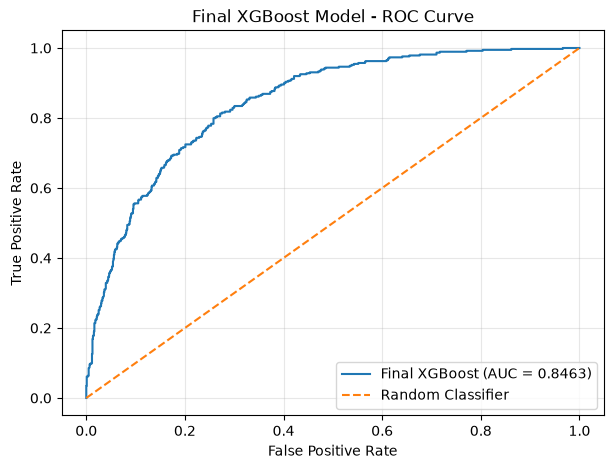

In [44]:
fpr, tpr, _ = roc_curve(y_test, final_test_probabilities)

final_roc_auc = roc_auc_score(
    y_test, final_test_probabilities
)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr, tpr,
    label=f"Final XGBoost (AUC = {final_roc_auc:.4f})"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final XGBoost Model - ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Model Comparison and Final Selection

Three modeling approaches were evaluated to identify the most suitable model for customer churn prediction: Logistic Regression, XGBoost with class weighting, and XGBoost with Random Undersampling. Logistic Regression was used as the baseline model and achieved an accuracy of 76.22%, precision of 53.99%, recall of 70.59%, F1-score of 61.18%, ROC-AUC of 0.8416, and PR-AUC of 0.6327 on the test set.

The original XGBoost model, using `scale_pos_weight`, achieved better performance across all evaluation metrics, with an accuracy of 76.44%, precision of 54.07%, recall of 74.60%, F1-score of 62.70%, ROC-AUC of 0.8463, and PR-AUC of 0.6622. Its final evaluation was confirmed after retraining the selected model using the training dataset and evaluating it on the independent test set.

An additional experiment using Random Undersampling was conducted to investigate the effect of reducing the majority class. During cross-validation, this approach increased recall from 77.59% to 80.60%. However, the F1-score slightly decreased from 0.6316 to 0.6302, while PR-AUC remained almost unchanged at 0.6622. This indicated that undersampling improved the detection of churn cases but did not provide an overall improvement in model performance.

Based on these findings, the original XGBoost model using `scale_pos_weight` was selected as the final predictive model. It achieved the best overall test performance and provided a better balance between precision and recall. Logistic Regression was retained as the baseline model, while Random Undersampling was documented as an additional experiment. The selected XGBoost model will be used in the next stages of the ModelGuard project, including experiment tracking, model monitoring, governance, and deployment.

In [47]:
import json
import joblib
from pathlib import Path

# Create artifacts directory
artifacts_dir = Path.cwd() / "artifacts"
artifacts_dir.mkdir(parents=True, exist_ok=True)

# 1. Save trained models
joblib.dump(
    final_model,
    artifacts_dir / "logistic_regression.joblib"
)

joblib.dump(
    final_xgb_model,
    artifacts_dir / "final_xgboost_model.joblib"
)

# 2. Collect Logistic Regression results
lr_cv_results = (
    cv_comparison.set_index("Model").to_dict(orient="index")
)

lr_test_results = (
    test_comparison.to_dict(orient="records")
)

# 3. Collect XGBoost results
xgb_cv_data = xgb_cv_results.to_dict(orient="records")[0]

xgb_test_data = xgb_test_results

xgb_tuning_data = {
    "best_parameters": xgb_search.best_params_,
    "best_cv_f1": float(xgb_search.best_score_),
    "selected_threshold": float(final_threshold)
}

# 4. Collect Random Undersampling results
undersampling_data = (
    undersampling_summary.set_index("Metric").to_dict(orient="index")
)

# 5. Organize all results
model_results = {
    "logistic_regression": {
        "model_role": "Baseline",
        "cross_validation": lr_cv_results,
        "threshold_optimization": {
            "selected_threshold": float(best_threshold)
        },
        "test_results": lr_test_results
    },

    "xgboost": {
        "model_role": "Final Model",
        "cross_validation": xgb_cv_data,
        "hyperparameter_tuning": xgb_tuning_data,
        "test_results": xgb_test_data
    },

    "xgboost_undersampling": {
        "model_role": "Experimental",
        "cross_validation": undersampling_data
    }
}

# 6. Save results as JSON
results_path = artifacts_dir / "model_results.json"

with open(results_path, "w", encoding="utf-8") as file:
    json.dump(
        model_results,
        file,
        indent=4,
        ensure_ascii=False,
        default=float
    )

# 7. Display exported files
print("Export completed successfully!")
print("\nSaved files:")

for file_path in artifacts_dir.iterdir():
    print(f"- {file_path.name}")

print("\nArtifacts location:", artifacts_dir)

Export completed successfully!

Saved files:
- .ipynb_checkpoints
- final_xgboost_model.joblib
- logistic_regression.joblib
- model_results.json

Artifacts location: C:\Users\User\ModelGuard\artifacts
